In [1]:
# Standard library
import json
import os
import random
import time
import warnings
from functools import partial
from multiprocessing import Manager, Pool, TimeoutError

# Third-party libraries
import deepchem as dc
import numpy as np
import pandas as pd
import pubchempy as pcp
import rdkit
import sklearn
from rdkit import Chem
from pandarallel import pandarallel
from rdkit.Chem import AllChem, Draw, SaltRemover, rdmolops
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit import RDLogger
RDLogger.DisableLog("rdApp.warning")
RDLogger.DisableLog("rdApp.*")
from sklearn.decomposition import PCA
from tqdm import tqdm

# Jupyter / IPython
from IPython.display import clear_output
warnings.filterwarnings("ignore", category=pd.errors.SettingWithCopyWarning)

# Optional imports
# from sklearn.decomposition import TruncatedSVD
# import torch

clear_output()

In [2]:
def load_data(file_name: str) -> pd.DataFrame:
    """
    Load and preprocess PubChem bioassay data from a CSV file.

    Removes records without a PubChem compound ID, resolves conflicting
    activity outcomes by prioritizing inactive observations, removes
    inconclusive results, and standardizes column names.

    Args:
        file_name (str): Name of the CSV file located in
            '../data/bioassay_source_data/'.

    Returns:
        pd.DataFrame: Processed dataframe containing the PubChem compound
            ID (`pubchem_cid`), SMILES representation (`smiles`), and
            activity outcome (`PUBCHEM_ACTIVITY_OUTCOME`) for each compound.
    """
    df = pd.read_csv(f"../data/bioassay_source_data/{file_name}", low_memory=False)
    df = df[~df['PUBCHEM_CID'].isnull()]
    df['PUBCHEM_CID'] = df['PUBCHEM_CID'].astype(int)

    df = df.sort_values(by='PUBCHEM_ACTIVITY_OUTCOME', ascending=False)

    # If two tests are performed on a single compound with conflicting results
    # (one is active the other is inactive) -
    # drop the active observation and consider the compound inactive.
    df = df.drop_duplicates(subset='PUBCHEM_CID', keep='first')

    display(pd.DataFrame(df['PUBCHEM_ACTIVITY_OUTCOME'].value_counts()))

    df = df[['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES', 'PUBCHEM_ACTIVITY_OUTCOME']]
    df = df[df['PUBCHEM_ACTIVITY_OUTCOME'] != 'Inconclusive'].reset_index(drop=True)

    display(pd.DataFrame(df['PUBCHEM_ACTIVITY_OUTCOME'].value_counts()))

    df.rename({'PUBCHEM_CID': 'pubchem_cid',
               'PUBCHEM_EXT_DATASOURCE_SMILES': 'smiles'}, axis=1, inplace=True)

    print(f"Length of dataframe after processing: {len(df):,}")
    return df

In [3]:
def visualize_comps(smiles_list: pd.Series, col_for_legend: pd.Series = None, mols_per_row: int = 3, include_markdown: bool=True) -> None:
    """ 
    Visualize molecules from SMILES strings in a grid, with optional legends.

    Converts SMILES strings to RDKit molecule objects and displays them in a
    grid image. Optionally uses values from a provided Series as molecule
    legends and limits the visualization to the first 100 molecules.

    Args:
        smiles_list (pd.Series): Series containing SMILES representations
            of the molecules to visualize.
        col_for_legend (pd.Series, optional): Series containing values to
            display as legends beneath the corresponding molecules. Its name
            is used to generate a formatted column title when markdown output
            is enabled. Defaults to None.
        mols_per_row (int, optional): Number of molecules to display per row.
            Defaults to 3.
        include_markdown (bool, optional): Whether to prepare a formatted
            column title for optional Markdown headings. Defaults to True.

    Returns:
        None: Displays a grid image of the molecules.
    """
    if include_markdown:
        column_title = col_for_legend.name.replace("_", " ").title()
        # display(Markdown(f"## Examples of Extreme {column_title}:"))
        # display(Markdown(f"Legend for figure represents numeric value of {column_title}."))
    smiles_list = list(smiles_list)
    
    if col_for_legend is not None:
        col_for_legend = list(col_for_legend.astype(str))
    else:
        col_for_legend = [""] * len(smiles_list)
#     col_for_legend = list(col_for_legend)

    if len(smiles_list) > 100:
        print("More than 100 smiles provided. List filtered to smaller set")
        smiles_list = smiles_list[0:100]
        
    every_mol = []
    every_legend = []
    
    low_index = 0
    
    while low_index < len(smiles_list):
        high_index = low_index + mols_per_row
        row_smiles = smiles_list[low_index: high_index]
        mols = [Chem.MolFromSmiles(x) for x in row_smiles]
        
        
        every_mol.append(mols)
        
        if col_for_legend is not None:
            row_legend = col_for_legend[low_index: high_index]
            every_legend.append(row_legend)
        else:
            every_legend.append([""]*mols_per_row)
            
        low_index += mols_per_row

    display(Draw.MolsMatrixToGridImage(molsMatrix=every_mol, subImgSize=(300, 150), 
                                       legendsMatrix = every_legend))

### Load PubChem Bioassay CSV files downloaded from PubChem

In [4]:
app_df=load_data("AID_1285_datatable_all.csv")
app_df.rename({'PUBCHEM_ACTIVITY_OUTCOME':'app_inhibitor'},
                   axis=1, inplace=True)
app_df.head()

,count
PUBCHEM_ACTIVITY_OUTCOME,
Inactive,192124
Active,1590


,count
PUBCHEM_ACTIVITY_OUTCOME,
Inactive,192124
Active,1590


Length of dataframe after processing: 193,714


,pubchem_cid,smiles,app_inhibitor
0,2862774,CC1=C(SC(=C1C(=O)OC(C)C)NC(=O)C2CC=CCC2C(=O)O)C,Inactive
1,2262351,CN(C)CCCNC(=O)C1=CC=C(C=C1)CN(C2=CC=CC=C2)S(=O...,Inactive
2,663463,CCOC(=O)C1=C(N=C2C=CC(=CC2=C1)F)C,Inactive
3,9682237,CCNC(=S)N/N=C(\C)/C1=CC(=CC=C1)OC,Inactive
4,2116195,COC1=CC=CC=C1OCC(=O)N2C=C(C=N2)C(=O)C3=C(C(=CC...,Inactive


In [5]:
tau_df=load_data("AID_1468_datatable_all.csv")
tau_df.rename({'PUBCHEM_ACTIVITY_OUTCOME':'tau_inhibitor'},
                   axis=1, inplace=True)
tau_df.head()

,count
PUBCHEM_ACTIVITY_OUTCOME,
Inactive,250957
Inconclusive,19420
Active,1025


,count
PUBCHEM_ACTIVITY_OUTCOME,
Inactive,250957
Active,1025


Length of dataframe after processing: 251,982


,pubchem_cid,smiles,tau_inhibitor
0,2227226,C1=CC=C(C=C1)OC(=O)C2=CC=CC3=C2N=CC=C3,Inactive
1,843702,CCNC1=NN=C(S1)CCN2C(=C(C(=N2)C)Br)C,Inactive
2,2262203,CCOC1=CC=C(C=C1)N(CC(=O)NCCSC2=CC=CC=N2)S(=O)(...,Inactive
3,3964749,CC1=CC=C(C=C1)C2=CC=C(N2CC(=O)NC3=CC(=CC=C3)OC...,Inactive
4,662689,CC1=C(C(=CC=C1)C)N2C(=O)C3C(N(OC3C2=O)C4=CC=CC...,Inactive


### Combine the data for both the APP and Tau Protein Bioassays

Single dataframe, columns that indicate activity in each assay.

In [6]:
combined_df = pd.merge(tau_df, app_df, on=['pubchem_cid', 'smiles'], how='outer')

print(f"Length of combined dataframe: {len(combined_df):,}")
combined_df.sample(n=5)

Length of combined dataframe: 265,007


,pubchem_cid,smiles,tau_inhibitor,app_inhibitor
99138,2469376,CC(=O)C1=CC=C(C=C1)N2CCN(CC2)C(=O)C3=CC4=C(C=C...,Inactive,Inactive
236094,16028784,COC1=CC=CC(=C1)CN2C3=C(C=CC(=C3)C(=O)OCC4=CC=C...,Inactive,NaN
34233,754450,CCOC(=O)C1=CC(=C(NC1=O)C)C(=O)OCC,Inactive,Inactive
2218,67356,C1CN(CCN1CCCN2C3=CC=CC=C3SC4=C2C=C(C=C4)C(F)(F...,Inactive,NaN
254162,16758688,C[C@@H](C1=CC=CC=C1)N2C(=O)[C@H]3CC[C@@H]\4[C@...,Inactive,NaN


In [7]:
both_active = combined_df.loc[(combined_df['app_inhibitor'] == 'Active') & \
                              (combined_df['tau_inhibitor'] == 'Active')].reset_index(drop=True)

# both_active['pubchem_cid'] = both_active['pubchem_cid'].astype(int)
print(f"Number of active compounds for both assays: {len(both_active)}")
both_active.head()

Number of active compounds for both assays: 31


,pubchem_cid,smiles,tau_inhibitor,app_inhibitor
0,6099,CN(C)C1=CC2=C(C=C1)N=C3C=CC(=[N+](C)C)C=C3S2.[...,Active,Active
1,20992,C1=CC(=O)N(C1=O)CCCCCCN2C(=O)C=CC2=O,Active,Active
2,62770,C[C@H]1[C@H]([C@H](C[C@@H](O1)O[C@H]2C[C@@](CC...,Active,Active
3,121637,COC1=CC=C(C=C1)C2=CC(=O)C=CC2=O,Active,Active
4,260557,CN(C)C1=CC=C(C=C1)NC2=C(C(=O)C3=CC=CC=C3C2=O)Cl,Active,Active


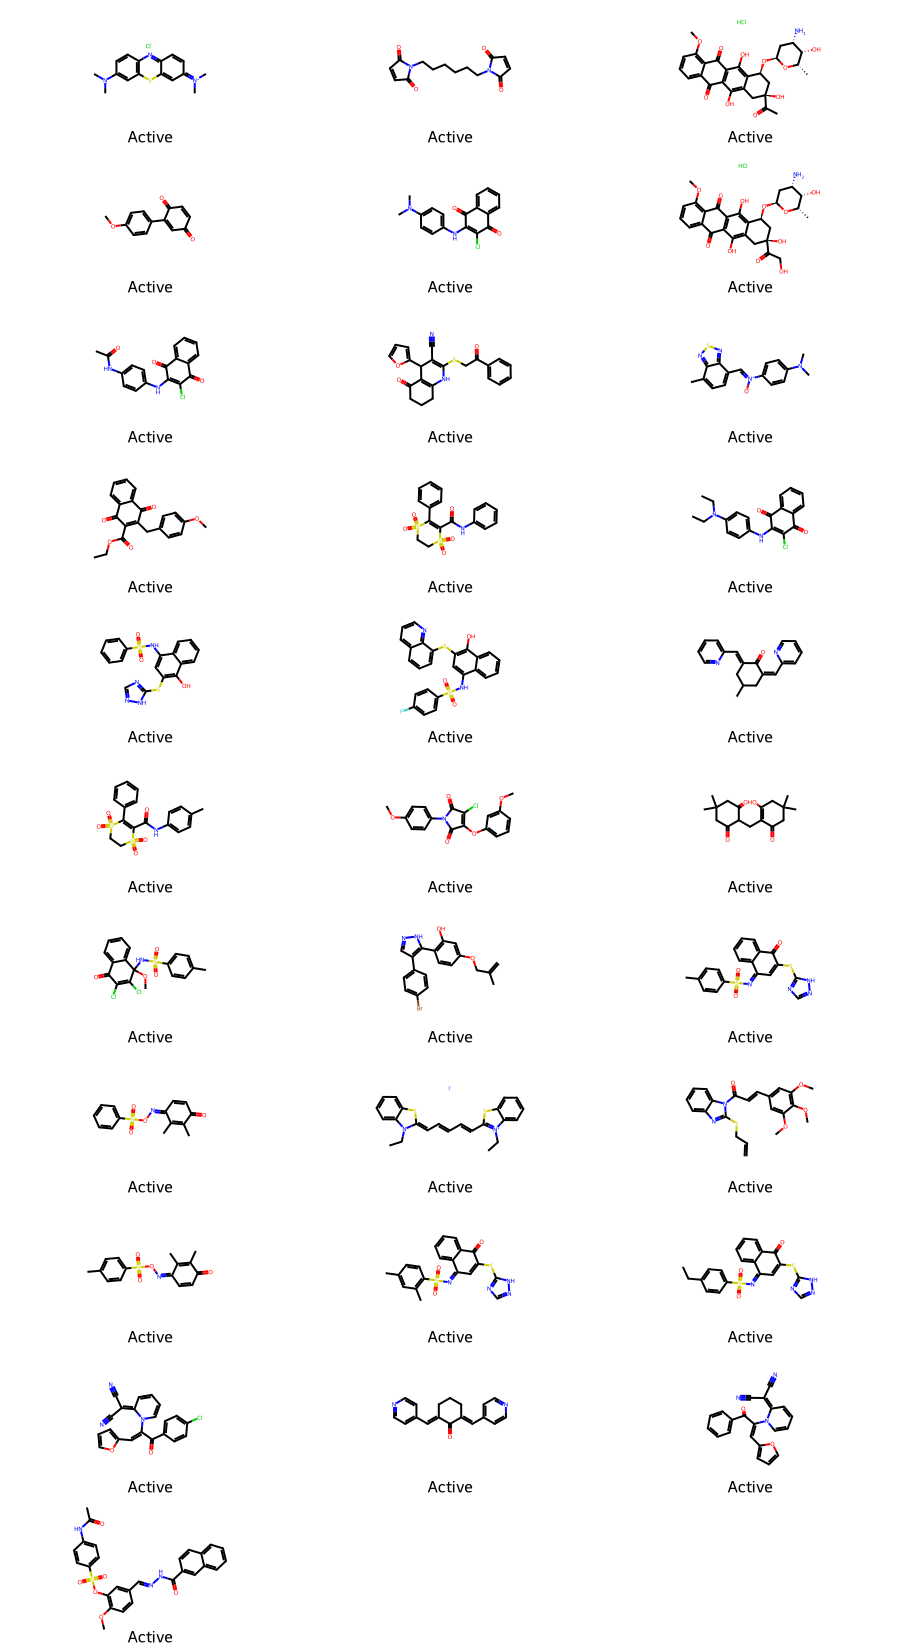

In [8]:
visualize_comps(both_active['smiles'], both_active['tau_inhibitor'])

### Save PubChem CIDS to Extract Compound Data from PubChem
* The txt files can be loaded directly into PubChem interface to get their other properties:
*   Inchi, InChIKey, Isomeric SMILES, molecular weight, xlogp, etc.

In [9]:
# in order to load the compound cids to pubchem and get metadata, need to write
# the data to a file as a string

resave_cids = False

if resave_cids:
    with open("../data/pubchem_cids/tau_compound_cids", 'a+') as f:
        dfAsString = tau_df['pubchem_cid'].to_string(header=True, index=False)
        f.write(dfAsString)

    with open("../data/pubchem_cids/app_compound_cids", 'a+') as f:
        dfAsString = app_df['pubchem_cid'].to_string(header=True, index=False)
        f.write(dfAsString)

### Load Compound Data and Properties from PubChem - Direct Export from PubChem
* The txt files can be loaded directly into PubChem interface to get their other properties:
*   Inchi, InChIKey, Isomeric SMILES, molecular weight, xlogp, etc.

In [10]:
# combined_df_copy = combined_df.copy() # backup - if needing to restart joins

In [11]:
# test = pd.read_pickle("../data/both_assays_pubchem_fp_graphs.pickle")
# test

In [12]:
# tau = test[~test['tau_inhibitor'].isnull()]
# tau = tau[['pubchem_cid', 'inchi','inchikey', 'cmpdname', 'isosmiles',  'cmpdsynonym',
#                     'mw', 'mf', 'polararea', 'complexity', 'xlogp', 'heavycnt',
#                     'hbonddonor', 'hbondacc', 'rotbonds']]


# app = test[~test['app_inhibitor'].isnull()]
# app = app[['pubchem_cid', 'inchi','inchikey', 'cmpdname', 'isosmiles',  'cmpdsynonym',
#                     'mw', 'mf', 'polararea', 'complexity', 'xlogp', 'heavycnt',
#                     'hbonddonor', 'hbondacc', 'rotbonds']]

In [13]:
### Dump Data - 

In [14]:
# tau.to_parquet("../data/bioassay_compounds_metadata/tau_pubchem_compounds.parquet.gz")
# app.to_parquet("../data/bioassay_compounds_metadata/app_pubchem_compounds.parquet.gz")

In [15]:
def load_compound_pubchem_metadata(file_name: str) -> pd.DataFrame:
    """ 
    Load and preprocess PubChem compound metadata from a Parquet file.

    Selects relevant compound identifiers, chemical descriptors, and
    molecular properties from the metadata dataset.

    Args:
        file_name (str): Name of the Parquet file located in
            '../data/bioassay_compounds_metadata/'.

    Returns:
        pd.DataFrame: Dataframe containing PubChem compound identifiers,
            chemical identifiers, synonyms, and molecular properties,
            including molecular weight, molecular formula, polar surface
            area, XLogP, hydrogen bond donors and acceptors, and rotatable
            bond count.
    """
    df=pd.read_parquet(f"../data/bioassay_compounds_metadata/{file_name}")

    keep_columns = ['pubchem_cid', 'inchi','inchikey', 'cmpdname', 'isosmiles',  'cmpdsynonym',
                    'mw', 'mf', 'polararea', 'complexity', 'xlogp', 'heavycnt',
                    'hbonddonor', 'hbondacc', 'rotbonds']

    df=df[keep_columns]
    # df.rename(columns={'cid': 'pubchem_cid'}, inplace=True)

    print(f"Number of compounds in {file_name} dataframe: {len(df):,}")
    print("-"*80)

    display(df.head(2))
    return df

In [16]:
## df after loading from pubchem - needed to get extra metadata

app_compounds=load_compound_pubchem_metadata("app_pubchem_compounds.parquet.gz")
tau_compounds=load_compound_pubchem_metadata("tau_pubchem_compounds.parquet.gz")

Number of compounds in app_pubchem_compounds.parquet.gz dataframe: 193,696
--------------------------------------------------------------------------------


,pubchem_cid,inchi,inchikey,cmpdname,isosmiles,cmpdsynonym,mw,mf,polararea,complexity,xlogp,heavycnt,hbonddonor,hbondacc,rotbonds
0,2227226,InChI=1S/C16H11NO2/c18-16(19-13-8-2-1-3-9-13)1...,GPMDYHKFDVDMLK-UHFFFAOYSA-N,8-Quinolinecarboxylic acid phenyl ester,C1=CC=C(C=C1)OC(=O)C2=CC=CC3=C2N=CC=C3,phenyl quinoline-8-carboxylate|8-quinolinecarb...,249.26,C16H11NO2,39.2,312.0,3.6,19,0,3,3
1,135420967,InChI=1S/C17H13NO4/c1-21-12-8-6-11(7-9-12)18-1...,RUCHDIHJKMGHHH-UHFFFAOYSA-N,"3-[(4-methoxyanilino)methylene]-2H-chromene-2,...",COC1=CC=C(C=C1)N=CC2=C(C3=CC=CC=C3OC2=O)O,364602-08-4|AGN-PC-0LQKC2|Oprea1_586022|MLS000...,295.29,C17H13NO4,68.1,477.0,2.8,22,1,5,3


Number of compounds in tau_pubchem_compounds.parquet.gz dataframe: 251,953
--------------------------------------------------------------------------------


,pubchem_cid,inchi,inchikey,cmpdname,isosmiles,cmpdsynonym,mw,mf,polararea,complexity,xlogp,heavycnt,hbonddonor,hbondacc,rotbonds
0,2227226,InChI=1S/C16H11NO2/c18-16(19-13-8-2-1-3-9-13)1...,GPMDYHKFDVDMLK-UHFFFAOYSA-N,8-Quinolinecarboxylic acid phenyl ester,C1=CC=C(C=C1)OC(=O)C2=CC=CC3=C2N=CC=C3,phenyl quinoline-8-carboxylate|8-quinolinecarb...,249.26,C16H11NO2,39.2,312.0,3.6,19,0,3,3
1,135420967,InChI=1S/C17H13NO4/c1-21-12-8-6-11(7-9-12)18-1...,RUCHDIHJKMGHHH-UHFFFAOYSA-N,"3-[(4-methoxyanilino)methylene]-2H-chromene-2,...",COC1=CC=C(C=C1)N=CC2=C(C3=CC=CC=C3OC2=O)O,364602-08-4|AGN-PC-0LQKC2|Oprea1_586022|MLS000...,295.29,C17H13NO4,68.1,477.0,2.8,22,1,5,3


### Combine All Compound and Screening Data into Single DF

In [17]:
# pubchem_metadata for every compound in either assay
all_metadata_df=app_compounds.set_index(['inchi',
                                            'pubchem_cid']).combine_first(tau_compounds.set_index(['inchi',
                                                                                                'pubchem_cid']))
all_metadata_df=all_metadata_df.reset_index()

combined_w_pubchem = combined_df.merge(all_metadata_df, how='left', on='pubchem_cid')
combined_w_pubchem=combined_w_pubchem.drop_duplicates(subset='inchi').reset_index(drop=True)

print(f"Number of compounds tested in either bioassay with PubChem metadata: {len(combined_w_pubchem):,}")

display(combined_w_pubchem.head(3))

Number of compounds tested in either bioassay with PubChem metadata: 264,966


,pubchem_cid,smiles,tau_inhibitor,app_inhibitor,inchi,inchikey,cmpdname,isosmiles,cmpdsynonym,mw,mf,polararea,complexity,xlogp,heavycnt,hbonddonor,hbondacc,rotbonds
0,72,C1=CC(=C(C=C1C(=O)O)O)O,Inactive,NaN,InChI=1S/C7H6O4/c8-5-2-1-4(7(10)11)3-6(5)9/h1-...,YQUVCSBJEUQKSH-UHFFFAOYSA-N,"3,4-Dihydroxybenzoic acid",C1=CC(=C(C=C1C(=O)O)O)O,"3,4-DIHYDROXYBENZOIC ACID|protocatechuic acid|...",154.12,C7H6O4,77.8,157.0,1.1,11.0,3.0,4.0,1.0
1,119,C(CC(=O)O)CN,Inactive,Inactive,"InChI=1S/C4H9NO2/c5-3-1-2-4(6)7/h1-3,5H2,(H,6,7)",BTCSSZJGUNDROE-UHFFFAOYSA-N,gamma-Aminobutyric acid,C(CC(=O)O)CN,4-aminobutyric acid|4-Aminobutanoic acid|gamma...,103.12,C4H9NO2,63.3,62.7,-3.2,7.0,2.0,3.0,3.0
2,178,CC(=O)N,Inactive,NaN,"InChI=1S/C2H5NO/c1-2(3)4/h1H3,(H2,3,4)",DLFVBJFMPXGRIB-UHFFFAOYSA-N,Acetamide,CC(=O)N,acetamide|60-35-5|Ethanamide|Acetic acid amide...,59.07,C2H5NO,43.1,33.0,-0.9,4.0,1.0,1.0,0.0


<!-- ### Load Formatted Training Data - Strip Compounds and Regenerate Graphs / FPs -->

In [18]:
# training_data=pd.read_pickle("/home/paperspace/Desktop/DL_Project/data/full_data_fp_pca_2023Dec22.pickle")
# training_data.drop(columns=['Smiles'], inplace=True)
# print(len(training_data))
# training_data.head()


### Strip Salts, Neutralize Charges, and Generate Canonical Tautomers

In [19]:
def canonical_tautomer_preserve_stereo(mol: Chem.Mol) -> str:
    """
    Generate the canonical tautomer of a molecule.

    Args:
        mol (Chem.Mol): RDKit molecule object

    Returns:
        str - canonical tautomer SMILES string
    """
    if mol is None:
        return None

    params = rdMolStandardize.CleanupParameters()
    params.tautomerRemoveSp3Stereo = False
    params.tautomerRemoveBondStereo = False

    enumerator = rdMolStandardize.TautomerEnumerator(params)
    tautomer = enumerator.Canonicalize(mol)

    return Chem.MolToSmiles(tautomer, isomericSmiles=True)

# https://www.rdkit.org/docs/source/rdkit.Chem.SaltRemover.html

def strip_salts_neutralize(smiles: str) -> str:
    """
    Remove salts, neutralize a molecule, and generate its canonical tautomer.

    Processes a SMILES string using RDKit to generate the original canonical
    SMILES, salt-stripped and uncharged SMILES, formal charge, and canonical
    tautomer.

    Args:
        smiles (str): SMILES representation of the input molecule.

    Returns:
        tuple[str, str, int, str]: A tuple containing:
            - canonical_smiles (str): Canonical SMILES of the original molecule.
            - uncharged_smiles (str): SMILES after salt removal and neutralization.
            - updated_charge (int): Formal charge of the neutralized molecule.
            - canonical_tautomer (str): Canonical tautomer SMILES of the
              neutralized molecule.
    """
    # strip salts
    remover = SaltRemover.SaltRemover()
    mol = Chem.MolFromSmiles(smiles)
    no_salt_mol = remover.StripMol(mol)
    
    # neutralize charges
    un = rdMolStandardize.Uncharger()
    uncharged_mol=un.uncharge(no_salt_mol)
    # uncharged_smiles=Chem.MolToSmiles(uncharged_mol)
    
    ## integer value of the molecule
    # updated_charge=rdmolops.GetFormalCharge(uncharged_mol)
    isomeric_canonical_smiles=Chem.MolToSmiles(uncharged_mol, isomericSmiles=True)

    # canonical tautomer for the molecule - removes stereochemistry
    # canonical_tautomer = Chem.MolToSmiles(rdMolStandardize.CanonicalTautomer(uncharged_mol))

    try:
        canonical_tautomer_smiles = canonical_tautomer_preserve_stereo(
        Chem.MolFromSmiles(isomeric_canonical_smiles)
        )
    except Exception as e:
        print(f"Failed SMILES: {isomeric_canonical_smiles}")
        raise RuntimeError(f"Tautomerization failed for {isomeric_canonical_smiles}") from e

    # canonical_tautomer = canonical_tautomer_preserve_stereo(Chem.MolFromSmiles(isomeric_canonical_smiles, isomericSmiles=True))

    return isomeric_canonical_smiles, canonical_tautomer_smiles

In [20]:
def safe_strip_salts_neutralize(smiles):
    try:
        if not isinstance(smiles, str) or not smiles.strip():
            raise ValueError("Missing or invalid SMILES")

        result = strip_salts_neutralize(smiles)

        # Return results plus an empty error field
        return (*result, None)

    except Exception as e:
        # Return only serializable values; don't return the exception itself
        return (None, None, None, None, f"{type(e).__name__}: {e}")

In [21]:
pandarallel.initialize(
    nb_workers=8,
    progress_bar=True
)

INFO: Pandarallel will run on 8 workers.
INFO: Pandarallel will use Memory file system to transfer data between the main process and workers.


In [22]:
## if pubchem doesn't provide isomeric smiles - fill in with 'normal' smiles
print(f"Number of null isomeric smiles: {combined_w_pubchem['isosmiles'].isnull().sum():,}")

## fill in 
combined_w_pubchem['isosmiles'] = np.where(combined_w_pubchem['isosmiles'].isnull(),
                                             combined_w_pubchem['smiles'],
                                             combined_w_pubchem['isosmiles'])

# training_data = combined_w_pubchem.tail(50)
training_data = combined_w_pubchem.copy()

print(f"Number of compounds in training data: {len(training_data):,}")

Number of null isomeric smiles: 1
Number of compounds in training data: 264,966


In [23]:
%%time 

sanitization_results = training_data["isosmiles"].parallel_apply(
    safe_strip_salts_neutralize
)

training_data[
    [
       # "sanitized_uncharged_smiles",
        "canonical_sanitized_iso_smiles",
        #"cleaned_charge_integer",
        "canonical_tautomer_smiles",
        "error"
    ]
] = pd.DataFrame(sanitization_results.tolist(), index=training_data.index)

CPU times: user 6.1 s, sys: 1.21 s, total: 7.31 s
Wall time: 8min 53s


In [24]:
iso_smiles_dups = training_data[training_data['canonical_sanitized_iso_smiles'].duplicated()]

print(f"Number of duplicate isomeric smiles: {len(iso_smiles_dups):,}")

tautomer_dups = list(training_data[training_data['canonical_tautomer_smiles'].duplicated()]['canonical_tautomer_smiles'])
tautomer_dups = training_data[training_data['canonical_tautomer_smiles'].isin(tautomer_dups)].sort_values(by='canonical_tautomer_smiles')

print(f"Number of duplicate tautomeric smiles: {len(tautomer_dups):,}")

Number of duplicate isomeric smiles: 510
Number of duplicate tautomeric smiles: 1,456



### Visualize Tautomers - Confirm Existence

In [25]:
## have duplicate isomeric smiles - therefore can't be tautomers
fake_tautomers = tautomer_dups[tautomer_dups['canonical_sanitized_iso_smiles'].duplicated()]

## if there are duplicate canoical tautomeric smiles because stereochemistry is removed - exclude
to_not_consider = tautomer_dups[tautomer_dups['inchikey'].fillna("").str.contains("-UHFFFAOYSA-")]['canonical_tautomer_smiles']
real_dups = tautomer_dups[~tautomer_dups['canonical_tautomer_smiles'].isin(fake_tautomers['canonical_tautomer_smiles'])]
real_tautomers = real_dups[~real_dups['canonical_tautomer_smiles'].isin(to_not_consider)].sort_values(by='canonical_tautomer_smiles')

In [26]:
# real_tautomers = real_dups[~real_dups['canonical_sanitized_iso_smiles'].isin(to_not_consider)].sort_values(by='canonical_sanitized_iso_smiles')

fake_tautomers.sort_values(by='canonical_tautomer_smiles')

,pubchem_cid,smiles,tau_inhibitor,app_inhibitor,inchi,inchikey,cmpdname,isosmiles,cmpdsynonym,mw,...,polararea,complexity,xlogp,heavycnt,hbonddonor,hbondacc,rotbonds,canonical_sanitized_iso_smiles,canonical_tautomer_smiles,error
186328,5739014,C1COCCN1CCSC2=NC3=C(C4=C(N3)C=CC(=C4)Br)N=N2.Cl,NaN,Inactive,InChI=1S/C15H16BrN5OS.ClH/c16-10-1-2-12-11(9-1...,CJLQZPSXTQKTIM-UHFFFAOYSA-N,"8-bromo-3-[(2-morpholin-4-ylethyl)thio]-5H-[1,...",C1COCCN1CCSC2=NC3=C(C4=C(N3)C=CC(=C4)Br)N=N2.Cl,SMR000033716|8-bromo-3-[(2-morpholin-4-ylethyl...,430.80,...,92.2,400.0,NaN,24.0,2.0,6.0,4.0,Brc1ccc2[nH]c3nc(SCCN4CCOCC4)nnc3c2c1,Brc1ccc2[nH]c3nc(SCCN4CCOCC4)nnc3c2c1,None
1715,26758,C[C@H](CC1=CC=CC=C1)N(C)CC#C.Cl,Inactive,NaN,InChI=1S/C13H17N.ClH/c1-4-10-14(3)12(2)11-13-8...,IYETZZCWLLUHIJ-UTONKHPSSA-N,Selegiline hydrochloride,C[C@H](CC1=CC=CC=C1)N(C)CC#C.Cl,Selegiline hydrochloride|14611-52-0|Eldepryl|S...,223.74,...,3.2,195.0,NaN,15.0,1.0,1.0,4.0,C#CCN(C)[C@H](C)Cc1ccccc1,C#CCN(C)[C@H](C)Cc1ccccc1,None
3650,189406,CN1CCC=C(C1)C(=O)OCC#C.Br,Inactive,NaN,InChI=1S/C10H13NO2.BrH/c1-3-7-13-10(12)9-5-4-6...,LRPUAFALRBYLTA-UHFFFAOYSA-N,Arecaidine propargyl ester hydrobromide,CN1CCC=C(C1)C(=O)OCC#C.Br,Arecaidine propargyl ester hydrobromide|116511...,260.13,...,29.5,272.0,NaN,14.0,1.0,3.0,3.0,C#CCOC(=O)C1=CCCN(C)C1,C#CCOC(=O)C1=CCCN(C)C1,None
266,2229,CN1CCC=C(C1)C(=O)OCC#C,Inactive,NaN,InChI=1S/C10H13NO2/c1-3-7-13-10(12)9-5-4-6-11(...,SPHRJZBOFYIKMC-UHFFFAOYSA-N,Arecaidine propargyl ester,CN1CCC=C(C1)C(=O)OCC#C,Arecaidine propargyl ester|35516-99-5|prop-2-y...,179.22,...,29.5,272.0,0.5,13.0,0.0,3.0,3.0,C#CCOC(=O)C1=CCCN(C)C1,C#CCOC(=O)C1=CCCN(C)C1,None
253461,16757912,C1CCN2C[C@H]3C[C@@H](C2C1)CN4C3CCCC4.I,Inactive,NaN,InChI=1S/C15H26N2.HI/c1-3-7-16-11-13-9-12(14(1...,GNYRFSRGJVIYQB-GPJJVDBKSA-N,"(1R,9R)-7,15-diazatetracyclo[7.7.1.02,7.010,15...",C1CCN2C[C@H]3C[C@@H](C2C1)CN4C3CCCC4.I,CHEMBL1734623|NCGC00095337-01,362.29,...,6.5,263.0,NaN,18.0,1.0,2.0,0.0,C1CCN2C[C@H]3C[C@H](CN4CCCCC34)C2C1,C1CCN2C[C@H]3C[C@H](CN4CCCCC34)C2C1,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255585,23581808,C1CN(CCN1CC2=CC3=C(C=C2)OCO3)C4=NC=CC=N4.O.Cl,Inactive,NaN,InChI=1S/C16H18N4O2.ClH.H2O/c1-4-17-16(18-5-1)...,WPPIVKOINGQRTL-UHFFFAOYSA-N,"2-[4-(1,3-Benzodioxol-5-ylmethyl)piperazin-1-y...",C1CN(CCN1CC2=CC3=C(C=C2)OCO3)C4=NC=CC=N4.O.Cl,SMR000449302|MLS000758225|MLS001423975|CHEMBL4...,352.81,...,51.7,356.0,NaN,24.0,2.0,7.0,3.0,c1cnc(N2CCN(Cc3ccc4c(c3)OCO4)CC2)nc1,c1cnc(N2CCN(Cc3ccc4c(c3)OCO4)CC2)nc1,None
210339,11957664,C1CN(CCN1CC2=CC3=C(C=C2)OCO3)C4=NC=CC=N4.C(=C\...,Inactive,NaN,InChI=1S/C16H18N4O2.C4H4O4/c1-4-17-16(18-5-1)2...,DKGOFBARSQSLOW-BTJKTKAUSA-N,Piribedil maleate,C1CN(CCN1CC2=CC3=C(C=C2)OCO3)C4=NC=CC=N4.C(=C\...,"Piribedil maleate|937719-94-3|2-[4-(1,3-Benzod...",414.40,...,125.0,475.0,NaN,30.0,2.0,10.0,5.0,c1cnc(N2CCN(Cc3ccc4c(c3)OCO4)CC2)nc1,c1cnc(N2CCN(Cc3ccc4c(c3)OCO4)CC2)nc1,None
3678,198284,CS(=O)(=O)O.C1CN(CCN1CC2=CC3=C(C=C2)OCO3)C4=NC...,Inactive,Inactive,InChI=1S/C16H18N4O2.CH4O3S/c1-4-17-16(18-5-1)2...,DEZKFCIOSKCCHK-UHFFFAOYSA-N,Piribedil mesylate,CS(=O)(=O)O.C1CN(CCN1CC2=CC3=C(C=C2)OCO3)C4=NC...,Piribedil mesylate|Piribedil monomethylsulfona...,394.40,...,114.0,449.0,NaN,27.0,1.0,9.0,3.0,c1cnc(N2CCN(Cc3ccc4c(c3)OCO4)CC2)nc1,c1cnc(N2CCN(Cc3ccc4c(c3)OCO4)CC2)nc1,None
250035,16196049,CC1=CC=C(C=C1)S(=O)(=O)[O-].C1=CC2=C(C3=C(C=CC...,NaN,Inactive,InChI=1S/C12H8N2.C7H8O3S/c1-3-9-5-6-10-4-2-8-1...,TUHNJTOLXCFPHY-UHFFFAOYSA-N,"4-Methylbenzenesulfonate;1,10-phenanthrolin-10...",CC1=CC=C(C=C1)S(=O)(=O)[O-].C1=CC2=C(C3=C(C=CC...,MLS001004432|HMS2691F20|SMR000348007,352.40,...,92.6,398.0,NaN,25.0,1.0,4.0,0.0,c1cnc2c(c1)ccc1cccnc12,c1cnc2c(c1)ccc1cccnc12,None


,inchikey,smiles,canonical_sanitized_iso_smiles,canonical_tautomer_smiles
185254,ICTXHFFSOAJUMG-OQPPHWFISA-N,C[C@]12CCC3C(C1CC[C@]2(C#C)O)CCC4=C3CCC(=O)C4,C#C[C@]1(O)CCC2C3CCC4=C(CCC(=O)C4)C3CC[C@@]21C,C#C[C@]1(O)CCC2C3CC=C4CC(=O)CCC4C3CC[C@@]21C
253319,VIKNJXKGJWUCNN-RZXUBOOQSA-N,C[C@]12CCC3C(C1CC[C@]2(C#C)O)CCC4=CC(=O)CCC34,C#C[C@]1(O)CCC2C3CCC4=CC(=O)CCC4C3CC[C@@]21C,C#C[C@]1(O)CCC2C3CC=C4CC(=O)CCC4C3CC[C@@]21C
247654,ANFOXGNEKOWGDD-LGMDPLHJSA-N,COC1=CC=CC=C1C(=O)N/C(=C\C2=CC=C(C=C2)Br)/C(=O...,C=CCNC(=O)/C(=C/c1ccc(Br)cc1)NC(=O)c1ccccc1OC,C=CCNC(=O)C(Cc1ccc(Br)cc1)=NC(=O)c1ccccc1OC
90463,ANFOXGNEKOWGDD-GHRIWEEISA-N,COC1=CC=CC=C1C(=O)N/C(=C/C2=CC=C(C=C2)Br)/C(=O...,C=CCNC(=O)/C(=C\c1ccc(Br)cc1)NC(=O)c1ccccc1OC,C=CCNC(=O)C(Cc1ccc(Br)cc1)=NC(=O)c1ccccc1OC
83773,VPFGPICGSKBJHU-LGMDPLHJSA-N,C=CCNC(=O)/C(=C/C1=CC(=CC=C1)[N+](=O)[O-])/NC(...,C=CCNC(=O)/C(=C/c1cccc([N+](=O)[O-])c1)NC(=O)c...,C=CCNC(=O)C(Cc1cccc([N+](=O)[O-])c1)=NC(=O)c1c...
187708,VPFGPICGSKBJHU-GHRIWEEISA-N,C=CCNC(=O)/C(=C\C1=CC(=CC=C1)[N+](=O)[O-])/NC(...,C=CCNC(=O)/C(=C\c1cccc([N+](=O)[O-])c1)NC(=O)c...,C=CCNC(=O)C(Cc1cccc([N+](=O)[O-])c1)=NC(=O)c1c...
186596,YCCJZCTZUZBKPQ-LTGZKZEYSA-N,C=CCOC(=O)/C(=C\C1=CC=CC2=CC=CC=C21)/NC(=O)C3=...,C=CCOC(=O)/C(=C\c1cccc2ccccc12)NC(=O)c1ccccc1,C=CCOC(=O)C(Cc1cccc2ccccc12)=NC(=O)c1ccccc1
76661,YCCJZCTZUZBKPQ-PGMHBOJBSA-N,C=CCOC(=O)/C(=C/C1=CC=CC2=CC=CC=C21)/NC(=O)C3=...,C=CCOC(=O)/C(=C/c1cccc2ccccc12)NC(=O)c1ccccc1,C=CCOC(=O)C(Cc1cccc2ccccc12)=NC(=O)c1ccccc1
182345,UFKNVXBWMBITCM-XFFZJAGNSA-N,CC1=NN(C(=O)C1/C=C\2/C(=O)NC(=S)N2)C3=CC=CC=C3,CC1=NN(c2ccccc2)C(=O)C1/C=C1\NC(=S)NC1=O,C=c1[nH]n(-c2ccccc2)c(=O)c1=Cc1[nH]c(=S)[nH]c1O
251289,UFKNVXBWMBITCM-YRNVUSSQSA-N,CC1=NN(C(=O)C1/C=C/2\C(=O)NC(=S)N2)C3=CC=CC=C3,CC1=NN(c2ccccc2)C(=O)C1/C=C1/NC(=S)NC1=O,C=c1[nH]n(-c2ccccc2)c(=O)c1=Cc1[nH]c(=S)[nH]c1O


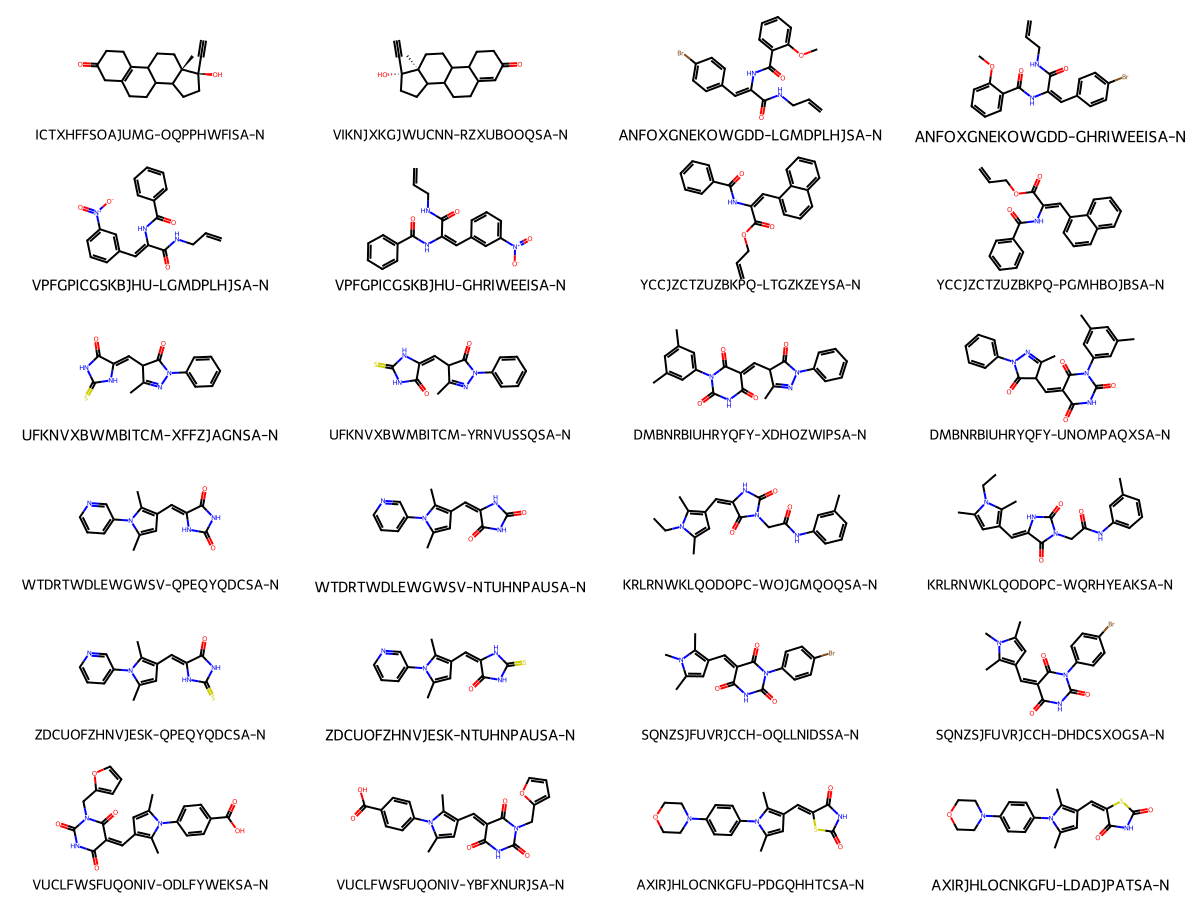

In [27]:
visualize = 24

sample_tautomers = real_tautomers.head(visualize)

display(sample_tautomers[['inchikey','smiles', 'canonical_sanitized_iso_smiles', 'canonical_tautomer_smiles']])

visualize_comps(sample_tautomers['smiles'], 
                sample_tautomers['inchikey'], mols_per_row=4)

### Use RDKit to Generate Morgan Fingerprints

In [28]:
def generate_morgan_fp(compound_data):
    """
    Generate a Morgan fingerprint while retaining failed records.

    compound_data contains the selected additional columns followed by SMILES.
    """
    compound_data = list(compound_data)
    smiles = compound_data[-1]

    try:
        if not isinstance(smiles, str) or not smiles.strip():
            raise ValueError("Missing or invalid SMILES")

        mol = Chem.MolFromSmiles(smiles)

        if mol is None:
            raise ValueError("RDKit could not parse SMILES")

        fp = AllChem.GetMorganFingerprintAsBitVect(
            mol,
            radius=2,
            nBits=2048,
            useChirality=True,
        )

        return compound_data + [fp.ToBitString(), None]

    except Exception as e:
        return compound_data + [
            None,
            f"{type(e).__name__}: {e}",
        ]


def fingerprints_main(
    df: pd.DataFrame,
    smiles_col: str,
    other_cols=None,
    processes=8,
) -> pd.DataFrame:
    """Generate Morgan fingerprints while retaining all input records."""
    if other_cols is None:
        other_cols = []

    selected_cols = other_cols + [smiles_col]
    input_data = df[selected_cols].values.tolist()

    with Pool(processes=processes) as pool:
        results = pool.map(generate_morgan_fp, input_data)

    return pd.DataFrame(
        results,
        columns=selected_cols + ["morgan_fp", "error"],
        index=df.index,
    )

In [29]:
# # generate morgan fingerprint 2048 length vector - multiprocessing

# def generate_morgan_fp(lst, compound_data):
#     """
#     Generate a Morgan fingerprint for a compound and append it to a shared list.

#     Args:
#         lst: Shared list for collecting processed compound data.
#         compound_data (list): Compound data where index 0 contains the InChI
#             and index 1 contains the isomeric SMILES string. 
#     """
#     # compound_data = list -> index 0 = inchi, index 1 = isomeric smile
#     mol = Chem.MolFromSmiles(compound_data[1])
#     fp = AllChem.GetMorganFingerprintAsBitVect(mol, useChirality=True, radius=2, nBits = 2048)
#     compound_data.append(fp.ToBitString()) # [inchi, iso_smile, fp]
#     lst.append(compound_data) # list of lists
#     # pbar.update(1)


# def fingerprints_main(df: pd.DataFrame, smiles_col: str, other_cols=[]) -> pd.DataFrame:
#     """ 
#     Generate Morgan fingerprints for compounds in parallel.

#     Extracts the specified columns from a DataFrame, computes 2048-bit Morgan
#     fingerprints using multiprocessing, and returns a DataFrame containing
#     the original selected columns and the fingerprint bit strings.

#     Args:
#         df (pd.DataFrame): Input DataFrame containing compound data.
#         smiles_col (str): Column containing isomeric SMILES strings.
#         other_cols (list, optional): Additional columns to preserve in the
#             output. Defaults to None.

#     Returns:
#         pd.DataFrame: DataFrame containing the selected input columns and
#             a 'morgan_fp' column with fingerprint bit strings.
#     """
#     fp_function_columns = df[other_cols+[smiles_col]].values.tolist()

#     # parallelize generation
#     if __name__ == '__main__':

#         # pbar = tqdm(total=len(df)/8)
#         dfs_list = Manager().list()
#         pool = Pool(processes=8)
#         res = pool.map_async(partial(generate_morgan_fp, dfs_list), fp_function_columns)
#         res.wait()
#         # pbar.close()

#     fp_df = pd.DataFrame(list(dfs_list), columns=other_cols+[smiles_col] + ['morgan_fp'])  # the final result
    
#     return fp_df

In [30]:
# ## 5 minutes
# def generate_int_fp(lst: list, data: str):
#     """ 
#      Convert a Morgan fingerprint bit string into a list of integers.

#     Args:
#         lst: Shared list used to collect the converted fingerprints.
#         data (str): Morgan fingerprint represented as a string of binary digits.
#     """
#     lst.append(list(map(int, data)))


# def expand_morgan_fps(df: pd.DataFrame, morgan_df_vals):
#     """ 
#     Expand Morgan fingerprint bit strings into individual integer features.

#     Converts each Morgan fingerprint string into a list of integer bits
#     and constructs a DataFrame in which each row represents a compound
#     and each column represents one fingerprint bit.

#     Args:
#         df (pd.DataFrame): DataFrame used to determine the number of
#             fingerprints for progress tracking.
#         morgan_df_vals: Iterable of Morgan fingerprint bit strings to expand.

#     Returns:
#         pd.DataFrame: DataFrame containing expanded Morgan fingerprints,
#             with each fingerprint represented as a row of integer values.
#     """
#     pbar = tqdm(total=len(df)/8)
#     dfs_list = Manager().list()
#     pool = Pool(processes=8)
#     res = pool.map_async(partial(generate_int_fp, dfs_list), morgan_df_vals)
#     res.wait()
#     pbar.close()
#     fp_df_expanded = pd.DataFrame(list(dfs_list))

#     return fp_df_expanded

In [31]:


def expand_morgan_fps(morgan_df: pd.DataFrame) -> pd.DataFrame:
    """Expand Morgan fingerprint bit strings into binary feature columns."""
    fp_array = np.frombuffer(
        "".join(morgan_df["morgan_fp"].tolist()).encode("ascii"),
        dtype=np.uint8,
    ).reshape(-1, 2048) - ord("0")

    return pd.DataFrame(
        fp_array,
        index=morgan_df.index,
        columns=[f"morgan_{i}" for i in range(2048)],
    )

In [ ]:
print(f"Number of compounds in training data: {len(training_data):,}")
## still generate from isomeric smiles
fp_df=fingerprints_main(training_data, 'canonical_sanitized_iso_smiles', ['inchikey'])
print(f"\nNumber of compounds in fingerprint dataframe: {len(fp_df):,}")

display(fp_df.head(3))

## deal with errors
fp_errors = fp_df[fp_df['error'].notnull()]

print(f"Compounds with errors generating fingerprints: {len(fp_errors):,}")
print(f"Inchikeys for errors: {fp_errors['inchikey'].unique()}")
print(f"Reasons for error:")

display(pd.DataFrame(fp_errors['error'].value_counts()))

fp_df = fp_df[~fp_df['error'].isnull()]

## expand into bit per column fingerprints
expanded_morgan_fp_df = expand_morgan_fps(fp_df)

print(f"\nNumber of compounds in expanded fingerprint dataframe: {len(expanded_morgan_fp_df):,}")
display(expanded_morgan_fp_df.head(3))

Number of compounds in training data: 264,966

Number of compounds in fingerprint dataframe: 264,966


,inchikey,canonical_sanitized_iso_smiles,morgan_fp,error
0,YQUVCSBJEUQKSH-UHFFFAOYSA-N,O=C(O)c1ccc(O)c(O)c1,0000000000000000000000000000000000000000000000...,None
1,BTCSSZJGUNDROE-UHFFFAOYSA-N,NCCCC(=O)O,0000000000000000000000000000000000000000000000...,None
2,DLFVBJFMPXGRIB-UHFFFAOYSA-N,CC(N)=O,0000000000000000000000000000000000000000000000...,None


Compounds with errors generating fingerprints: 2
Inchikeys for errors: ['KWGKDLIKAYFUFQ-UHFFFAOYSA-M' 'YOELKGUVMFIZHG-UHFFFAOYSA-N']
Reasons for error:


,count
error,
ValueError: Missing or invalid SMILES,1
ValueError: RDKit could not parse SMILES,1



Number of compounds in expanded fingerprint dataframe: 264,964


,morgan_0,morgan_1,morgan_2,morgan_3,morgan_4,morgan_5,morgan_6,morgan_7,morgan_8,morgan_9,...,morgan_2038,morgan_2039,morgan_2040,morgan_2041,morgan_2042,morgan_2043,morgan_2044,morgan_2045,morgan_2046,morgan_2047
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [50]:
training_data_clean = training_data[~training_data['inchikey'].isin(fp_errors['inchikey'])]
training_data_clean

,pubchem_cid,smiles,tau_inhibitor,app_inhibitor,inchi,inchikey,cmpdname,isosmiles,cmpdsynonym,mw,...,polararea,complexity,xlogp,heavycnt,hbonddonor,hbondacc,rotbonds,canonical_sanitized_iso_smiles,canonical_tautomer_smiles,error
0,72,C1=CC(=C(C=C1C(=O)O)O)O,Inactive,NaN,InChI=1S/C7H6O4/c8-5-2-1-4(7(10)11)3-6(5)9/h1-...,YQUVCSBJEUQKSH-UHFFFAOYSA-N,"3,4-Dihydroxybenzoic acid",C1=CC(=C(C=C1C(=O)O)O)O,"3,4-DIHYDROXYBENZOIC ACID|protocatechuic acid|...",154.12,...,77.8,157.0,1.1,11.0,3.0,4.0,1.0,O=C(O)c1ccc(O)c(O)c1,O=C(O)c1ccc(O)c(O)c1,None
1,119,C(CC(=O)O)CN,Inactive,Inactive,"InChI=1S/C4H9NO2/c5-3-1-2-4(6)7/h1-3,5H2,(H,6,7)",BTCSSZJGUNDROE-UHFFFAOYSA-N,gamma-Aminobutyric acid,C(CC(=O)O)CN,4-aminobutyric acid|4-Aminobutanoic acid|gamma...,103.12,...,63.3,62.7,-3.2,7.0,2.0,3.0,3.0,NCCCC(=O)O,NCCCC(=O)O,None
2,178,CC(=O)N,Inactive,NaN,"InChI=1S/C2H5NO/c1-2(3)4/h1H3,(H2,3,4)",DLFVBJFMPXGRIB-UHFFFAOYSA-N,Acetamide,CC(=O)N,acetamide|60-35-5|Ethanamide|Acetic acid amide...,59.07,...,43.1,33.0,-0.9,4.0,1.0,1.0,0.0,CC(N)=O,CC(N)=O,None
3,185,CC(=O)NC(CCC(=O)O)C(=O)O,Inactive,NaN,InChI=1S/C7H11NO5/c1-4(9)8-5(7(12)13)2-3-6(10)...,RFMMMVDNIPUKGG-UHFFFAOYSA-N,N-Acetyl-DL-glutamic acid,CC(=O)NC(CCC(=O)O)C(=O)O,2-acetamidopentanedioic acid|5817-08-3|N-Acety...,189.17,...,104.0,225.0,-1.8,13.0,3.0,5.0,5.0,CC(=O)NC(CCC(=O)O)C(=O)O,CC(=O)NC(CCC(=O)O)C(=O)O,None
4,187,CC(=O)OCC[N+](C)(C)C,Inactive,NaN,"InChI=1S/C7H16NO2/c1-7(9)10-6-5-8(2,3)4/h5-6H2...",OIPILFWXSMYKGL-UHFFFAOYSA-N,Acetylcholine,CC(=O)OCC[N+](C)(C)C,acetylcholine|Choline acetate|51-84-3|O-Acetyl...,146.21,...,26.3,115.0,0.2,10.0,0.0,2.0,4.0,CC(=O)OCC[N+](C)(C)C,CC(=O)OCC[N+](C)(C)C,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
264961,135873470,C1[C@H]2[C@@H](C(C(O2)N3C4=C(C(=O)NC(=N4)N)N=C...,Inactive,NaN,InChI=1S/C10H11BrN5O7P.Na/c11-9-13-3-6(14-10(1...,ZJRFCXHKYQVNFK-AAXXAWHJSA-M,"sodium;9-[(4aS,7aR)-7-hydroxy-2-oxido-2-oxo-4a...",C1[C@H]2[C@@H](C(C(O2)N3C4=C(C(=O)NC(=N4)N)N=C...,CHEMBL1436268|NCGC00093621-01,446.08,...,173.0,657.0,NaN,25.0,3.0,9.0,1.0,Nc1nc2c(nc(Br)n2C2O[C@H]3COP(=O)(O)O[C@@H]3C2O...,Nc1nc(=O)c2nc(Br)n(C3O[C@H]4COP(=O)(O)O[C@@H]4...,None
264962,135873472,CC([C@H]([C@H]1CNC2=C(N1)C(=O)NC(=N2)N)O)O.Cl.Cl,Inactive,NaN,InChI=1S/C9H15N5O3.2ClH/c1-3(15)6(16)4-2-11-7-...,RKSUYBCOVNCALL-CPDCYLOMSA-N,"(6R)-2-amino-6-[(1S)-1,2-dihydroxypropyl]-5,6,...",CC([C@H]([C@H]1CNC2=C(N1)C(=O)NC(=N2)N)O)O.Cl.Cl,CHEMBL1354914|NCGC00094425-01,314.17,...,132.0,405.0,NaN,19.0,8.0,6.0,2.0,CC(O)[C@@H](O)[C@H]1CNc2nc(N)[nH]c(=O)c2N1,CC(O)[C@@H](O)[C@H]1CNc2[nH]c(N)nc(=O)c2N1,None
264963,135916112,CC(=CCN1C=NC2=C1C(=NCN2)NOCC3=CC=CC=C3)C,Inactive,NaN,InChI=1S/C17H21N5O/c1-13(2)8-9-22-12-20-16-15(...,HBAXQUMVEIEHQT-UHFFFAOYSA-N,"7-(3-methylbut-2-enyl)-N-phenylmethoxy-2,3-dih...",CC(=CCN1C=NC2=C1C(=NCN2)NOCC3=CC=CC=C3)C,CHEMBL1865718|CCG-260135|NCGC00161074-01|NCGC0...,311.40,...,63.5,440.0,2.9,23.0,2.0,4.0,6.0,CC(C)=CCn1cnc2c1C(NOCc1ccccc1)=NCN2,CC(C)=CCn1cnc2c1C(=NOCc1ccccc1)NCN2,None
264964,146030959,C[C@H]1[C@H]2[C@H]3[C@@H](OC=C4[C@@]3([C@@H](O...,Inactive,NaN,InChI=1S/C27H27NO8/c1-10-14-15-16(20(31)23-22(...,QRFYGFOATRMXAG-RMHJXMDKSA-N,"(1R,2R,3Z,4S,6R,7S,11S,12R,13S,16S,18R,19S,22S...",C[C@H]1[C@H]2[C@H]3[C@@H](OC=C4[C@@]3([C@@H](O...,NCGC00017748-01,493.50,...,123.0,1110.0,-0.6,36.0,2.0,9.0,3.0,C[C@@H]1O[C@H]2C3=C(C(=O)[C@H]4O[C@@H]4[C@H]3O...,C[C@@H]1O[C@H]2C3=C(C(=O)[C@H]4O[C@@H]4[C@H]3O...,None


### Generate Principal Components

In [51]:
n_components = 3
pca = PCA

pca = PCA(n_components=n_components)
pca_arr = pca.fit_transform(expanded_morgan_fp_df)

In [ ]:
assert len(pca_arr) == len(expanded_morgan_fp_df) == len(training_data_clean)

assert (training_data_clean.index == expanded_morgan_fp_df.index).all()

In [62]:
training_data_clean['first_component_pca'] = [i[0] for i in pca_arr]
training_data_clean['second_component_pca'] = [i[1] for i in pca_arr]
training_data_clean['third_component_pca'] = [i[2] for i in pca_arr]

training_data_clean.head(3)

,pubchem_cid,smiles,tau_inhibitor,app_inhibitor,inchi,inchikey,cmpdname,isosmiles,cmpdsynonym,mw,...,heavycnt,hbonddonor,hbondacc,rotbonds,canonical_sanitized_iso_smiles,canonical_tautomer_smiles,error,first_component_pca,second_component_pca,third_component_pca
0,72,C1=CC(=C(C=C1C(=O)O)O)O,Inactive,NaN,InChI=1S/C7H6O4/c8-5-2-1-4(7(10)11)3-6(5)9/h1-...,YQUVCSBJEUQKSH-UHFFFAOYSA-N,"3,4-Dihydroxybenzoic acid",C1=CC(=C(C=C1C(=O)O)O)O,"3,4-DIHYDROXYBENZOIC ACID|protocatechuic acid|...",154.12,...,11.0,3.0,4.0,1.0,O=C(O)c1ccc(O)c(O)c1,O=C(O)c1ccc(O)c(O)c1,None,-0.157060,-0.216007,0.253408
1,119,C(CC(=O)O)CN,Inactive,Inactive,"InChI=1S/C4H9NO2/c5-3-1-2-4(6)7/h1-3,5H2,(H,6,7)",BTCSSZJGUNDROE-UHFFFAOYSA-N,gamma-Aminobutyric acid,C(CC(=O)O)CN,4-aminobutyric acid|4-Aminobutanoic acid|gamma...,103.12,...,7.0,2.0,3.0,3.0,NCCCC(=O)O,NCCCC(=O)O,None,-0.391345,-0.281649,0.255974
2,178,CC(=O)N,Inactive,NaN,"InChI=1S/C2H5NO/c1-2(3)4/h1H3,(H2,3,4)",DLFVBJFMPXGRIB-UHFFFAOYSA-N,Acetamide,CC(=O)N,acetamide|60-35-5|Ethanamide|Acetic acid amide...,59.07,...,4.0,1.0,1.0,0.0,CC(N)=O,CC(N)=O,None,-0.224835,-0.057156,-0.018688


In [ ]:
# previous_full_data=pd.read_pickle("/home/paperspace/Desktop/DL_Project/data/full_data_fp_pca_2023Dec22.pickle")

In [ ]:
# previous_full_data.drop(columns=["first_component_pca", "second_component_pca", 'third_component_pca'],
# errors='ignore', inplace=True)

In [ ]:
# all_data_cleaned['inchikey'].duplicated().sum()
# all_data_cleaned=all_data_cleaned.sort_values(by='cleaned', ascending=True)
# all_data_cleaned.drop_duplicates(subset='inchikey', inplace=True)
# all_data_cleaned.drop_duplicates(subset='sanitized_uncharged_smiles', inplace=True)

In [ ]:
# combined_w_fp = combined_w_pubchem.merge(fp_df, on=['inchi', 'isosmiles'], how='left')
# combined_w_fp = combined_w_fp[~combined_w_fp['morgan_fp'].isnull()].reset_index(drop=True) # if done properly should not have any null
# combined_w_fp = combined_w_fp.drop_duplicates(keep = 'first').reset_index(drop=True)

# print(f"Length of dataframe after calculating morgan fingerprints: {len(combined_w_fp):,}")

In [ ]:
# save csv file with pubchem metadata and morgan fps - pre-graph generation

# resave=False

# if resave:
#     combined_w_fp.to_csv("both_assays_pubchem_metadata_morgan_fp.csv")

### Use DeepChem to Generate Graph Representations of Compounds

In [63]:
%%time
# if per_atom_fragmentation=False ~ 9 minutes
# if true, too long, doesn't finish

# combined_w_graphs=all_data_cleaned.copy()

generate_graphs = False

if generate_graphs:

    featurizer=dc.feat.ConvMolFeaturizer(per_atom_fragmentation=False) # if True takes forever and large memory
    f = featurizer.featurize(training_data['canonical_tautomer_smiles'])
    training_data_clean['dc_graph'] = f

    training_data_clean.head(2)

CPU times: user 5 μs, sys: 0 ns, total: 5 μs
Wall time: 8.58 μs


### Join ChEMBL Data for Additional Compound Characteristics

The compound identifiers were loaded into Chembl to get additional metadata

In [64]:
def pull_chembl() -> pd.DataFrame:
    """ 
    Load and preprocess the ChEMBL compound database from a CSV file.

    Reads the ChEMBL database, parses its semicolon-delimited records,
    assigns column names from the header row, and filters the dataset
    to include only small molecules.

    Returns:
        pd.DataFrame: DataFrame containing ChEMBL small-molecule records,
            with the 'Inchi Key' column renamed to 'inchikey' and the
            'Smiles' column renamed to 'chembl_smiles'.
    """
    
    with open("../data/chembl/chembl_full_db.csv", 'r') as handle:
        chembl_file = handle.readlines()

    # chembl_file = chembl_file[:500000]
    chembl_file = [i.replace('"', "") for i in chembl_file]
    chembl_file = [i.replace('\n', "") for i in chembl_file]
    chembl_file = [row.split(";") for row in chembl_file]

    chembl_df = pd.DataFrame(chembl_file)
    chembl_columns = list(chembl_df.iloc[0])
    chembl_df = chembl_df.drop(0)
    chembl_df.columns = chembl_columns
    chembl_df = chembl_df.rename(columns={"Inchi Key": "inchikey"}, errors='ignore')
    chembl_df = chembl_df[chembl_df['Type'] == 'Small molecule']

    chembl_df.rename(columns={'Smiles': 'chembl_smiles'}, inplace=True, errors='ignore')

    return chembl_df

In [ ]:
## 40ish seconds
chembl_df_full = pull_chembl()

## filter down to only what we need
chembl_df_subset = chembl_df_full[chembl_df_full['inchikey'].isin(training_data_clean['inchikey'])]

print(f"Length of full chembl set: {len(chembl_df_full):,}")
print(f"Length of chembl_df_subset: {len(chembl_df_subset):,}")
print(f"Length of training_data: {len(training_data_clean):,}")

In [83]:
keep_columns = ['Name','chembl_smiles','inchikey',
                'Type', 'Molecular Weight','AlogP',
                'Polar Surface Area', 'HBA', 'HBD',
                '#RO5 Violations','#Rotatable Bonds',
                'Passes Ro3','QED Weighted',
                'CX Acidic pKa','CX Basic pKa',
                'CX LogP', 'CX LogD',
                'Aromatic Rings','Structure Type',
                'HBA (Lipinski)','HBD (Lipinski)',
                '#RO5 Violations (Lipinski)']

numeric_columns = ['Molecular Weight','AlogP',
                'Polar Surface Area', 'HBA', 'HBD',
                '#RO5 Violations','#Rotatable Bonds',
                'QED Weighted',
                'CX Acidic pKa','CX Basic pKa',
                'CX LogP', 'CX LogD',
                'Aromatic Rings',
                'HBA (Lipinski)','HBD (Lipinski)',
                '#RO5 Violations (Lipinski)']


# # filter to subset of compounds
chembl_df_subset = chembl_df_subset[keep_columns]

# # # format to allow future formatting
# chembl_df_subset = chembl_df_subset.replace("", -999)
# chembl_df_subset = chembl_df_subset.replace(np.nan, -999)
# chembl_df_subset = chembl_df_subset.replace("None", -999)
# chembl_df_subset = chembl_df_subset.replace(np.nan, -999)

# chembl_df_subset[numeric_columns] = chembl_df_subset[numeric_columns].apply(pd.to_numeric, axis = 1)
# chembl_df_subset = chembl_df_subset.replace(-999, np.nan)

chembl_df_subset[numeric_columns] = chembl_df_subset[numeric_columns].apply(
    pd.to_numeric, errors="coerce"
)
chembl_df_subset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 255158 entries, 18 to 2331700
Data columns (total 22 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Name                        255158 non-null  object 
 1   chembl_smiles               255158 non-null  object 
 2   inchikey                    255158 non-null  object 
 3   Type                        255158 non-null  object 
 4   Molecular Weight            255158 non-null  float64
 5   AlogP                       254962 non-null  float64
 6   Polar Surface Area          254962 non-null  float64
 7   HBA                         254962 non-null  float64
 8   HBD                         254962 non-null  float64
 9   #RO5 Violations             254962 non-null  float64
 10  #Rotatable Bonds            254962 non-null  float64
 11  Passes Ro3                  255158 non-null  object 
 12  QED Weighted                254962 non-null  float64
 13  CX Acidic pKa    

In [85]:


# chembl_df_full = chembl_df.sample

In [86]:
# sanitization_results = chembl_df_subset["chembl_smiles"].parallel_apply(
#     strip_salts_neutralize
# )

# chembl_df_subset[
#     [
#         # "sanitized_uncharged_smiles",
#         "canonical_sanitized_iso_smiles",
#         # "cleaned_charge_integer",
#         "canonical_tautomer_smiles"
#     ]
# ] = pd.DataFrame(sanitization_results.tolist(), index=chembl_df_subset.index)

In [87]:
chembl_df_subset['inchikey'].duplicated().sum()

0

In [88]:
chembl_df_subset.head()

,Name,chembl_smiles,inchikey,Type,Molecular Weight,AlogP,Polar Surface Area,HBA,HBD,#RO5 Violations,...,QED Weighted,CX Acidic pKa,CX Basic pKa,CX LogP,CX LogD,Aromatic Rings,Structure Type,HBA (Lipinski),HBD (Lipinski),#RO5 Violations (Lipinski)
18,,CC(=O)N1CCCC1c1nc2ccccc2n1Cc1ccccc1C,DHHHONGAUOAGCT-UHFFFAOYSA-N,Small molecule,333.44,4.08,38.13,3.0,0.0,0.0,...,0.72,NaN,4.48,3.58,3.58,3.0,MOL,4.0,0.0,0.0
20,,CCCCc1nc2cc(Cl)ccc2o1,NIFBGGGUYHSOQU-UHFFFAOYSA-N,Small molecule,209.68,3.82,26.03,2.0,0.0,0.0,...,0.77,NaN,0.63,3.64,3.64,2.0,MOL,2.0,0.0,0.0
24,,COc1cccc(-c2cc(C(F)(F)F)nc(-n3cncn3)n2)c1,UOJNPPIBMFRDNJ-UHFFFAOYSA-N,Small molecule,321.26,2.75,65.72,6.0,0.0,0.0,...,0.74,NaN,1.01,3.27,3.27,3.0,MOL,6.0,0.0,0.0
31,,Cc1[nH]c2ccccc2c1C(=O)CN1CCC2(CC1)OCCO2,OKIWVYPITFJCJI-UHFFFAOYSA-N,Small molecule,314.39,2.50,54.56,4.0,1.0,0.0,...,0.88,13.45,7.28,2.38,2.14,2.0,MOL,5.0,1.0,0.0
38,,CCCCC(=O)Nc1cc(C(=O)NCCc2ccccc2)ccc1Cl,JSNMRQNFXPVBTQ-UHFFFAOYSA-N,Small molecule,358.87,4.44,58.20,2.0,2.0,0.0,...,0.73,12.55,NaN,4.49,4.49,2.0,MOL,4.0,2.0,0.0


In [89]:
### metadata from SureChembl is for exploratory analysis - matching on inchikey is adequate
training_full_metadata = training_data_clean.merge(chembl_df_subset, how='outer', on = 'inchikey', suffixes=('_training', '_chembl'))
training_full_metadata

,pubchem_cid,smiles,tau_inhibitor,app_inhibitor,inchi,inchikey,cmpdname,isosmiles,cmpdsynonym,mw,...,QED Weighted,CX Acidic pKa,CX Basic pKa,CX LogP,CX LogD,Aromatic Rings,Structure Type,HBA (Lipinski),HBD (Lipinski),#RO5 Violations (Lipinski)
0,3147229,CN1C=C(C(=N1)C(=O)NC2=CC3=C(C=C2)N=C(N3)C4=CC=...,Inactive,Inactive,InChI=1S/C18H14N6O3/c1-23-10-15(24(26)27)16(22...,AAABHMIRDIOYOK-UHFFFAOYSA-N,1-methyl-4-nitro-N-(2-phenyl-1H-benzimidazol-5...,CN1C=C(C(=N1)C(=O)NC2=CC3=C(C=C2)N=C(N3)C4=CC=...,Oprea1_447631|Oprea1_833558|MLS000561332|CHEMB...,362.30,...,0.43,11.39,5.10,3.13,3.13,4.0,MOL,9.0,2.0,0.0
1,3333809,CC1=CC=C(C=C1)S(=O)(=O)C2CCCCC2=O,Inactive,Inactive,"InChI=1S/C13H16O3S/c1-10-6-8-11(9-7-10)17(15,1...",AAACOSUXEVDPSL-UHFFFAOYSA-N,2-(4-Methylbenzenesulfonyl)cyclohexan-1-one,CC1=CC=C(C=C1)S(=O)(=O)C2CCCCC2=O,2-(4-methylbenzenesulfonyl)cyclohexan-1-one|14...,252.33,...,0.81,10.58,NaN,2.92,2.92,1.0,MOL,3.0,0.0,0.0
2,2508673,C1CC1C2=NN=C(N2C3=CC=CC=C3)SCC(=O)NCCC4=CC=C(C...,Inactive,Inactive,InChI=1S/C21H21FN4OS/c22-17-10-6-15(7-11-17)12...,AAADJTFUPWEOSD-UHFFFAOYSA-N,"2-[(5-cyclopropyl-4-phenyl-4H-1,2,4-triazol-3-...",C1CC1C2=NN=C(N2C3=CC=CC=C3)SCC(=O)NCCC4=CC=C(C...,SMR000154917|MLS000569241|CHEMBL1337818|HMS229...,396.50,...,0.59,NaN,1.63,3.73,3.73,3.0,MOL,5.0,1.0,0.0
3,2850780,CC1=CC(=C(C=C1)CNC(C)COC)C,Inactive,Inactive,InChI=1S/C13H21NO/c1-10-5-6-13(11(2)7-10)8-14-...,AAAFNFZYVYYALD-UHFFFAOYSA-N,"(2,4-Dimethylbenzyl)(2-methoxy-1-methylethyl)a...",CC1=CC(=C(C=C1)CNC(C)COC)C,"MLS000061024|(2,4-dimethylbenzyl)(2-methoxy-1-...",207.31,...,0.80,NaN,9.00,2.93,1.33,1.0,MOL,2.0,1.0,0.0
4,16031807,CC1=C(C(=CC=C1)NS(=O)(=O)C2=CC3=C(C=C2)N(CCC3)...,Inactive,NaN,InChI=1S/C22H26N2O3S/c1-15-6-3-10-20(16(15)2)2...,AAALVBIWOWZUBR-UHFFFAOYSA-N,"1-(cyclobutylcarbonyl)-N-(2,3-dimethylphenyl)-...",CC1=C(C(=CC=C1)NS(=O)(=O)C2=CC3=C(C=C2)N(CCC3)...,CHEMBL1354533|HMS1901O01|ZINC8601020|NCGC00135...,398.50,...,0.84,7.96,NaN,4.30,4.21,2.0,MOL,5.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
264959,1476736,C1=CC=C(C=C1)C2=NC=C(S2)C3=NN(C=C3)S(=O)(=O)C4...,NaN,Inactive,"InChI=1S/C18H13N3O2S2/c22-25(23,15-9-5-2-6-10-...",ZZZPZDFBUDZIOU-UHFFFAOYSA-N,5-[1-(Benzenesulfonyl)-3-pyrazolyl]-2-phenylth...,C1=CC=C(C=C1)C2=NC=C(S2)C3=NN(C=C3)S(=O)(=O)C4...,318248-80-5|5-[1-(benzenesulfonyl)-3-pyrazolyl...,367.40,...,0.55,NaN,1.75,3.92,3.92,4.0,MOL,5.0,0.0,0.0
264960,6603339,CP(=O)(CCCN)O.Cl,Inactive,Inactive,"InChI=1S/C4H12NO2P.ClH/c1-8(6,7)4-2-3-5;/h2-5H...",ZZZRGSSRFFRTIE-UHFFFAOYSA-N,3-Aminopropyl(methyl)phosphinic acid hydrochlo...,CP(=O)(CCCN)O.Cl,3-Aminopropyl(methyl)phosphinic acid hydrochlo...,173.58,...,0.55,1.99,10.21,-2.76,-2.76,0.0,MOL,3.0,3.0,0.0
264961,649052,CC1=CC(=NO1)NC(=O)CSC2=NC(=NC3=CC=CC=C32)C4CCCCC4,Inactive,Inactive,InChI=1S/C20H22N4O2S/c1-13-11-17(24-26-13)22-1...,ZZZUBCPKFYJDFU-UHFFFAOYSA-N,2-(2-Cyclohexyl-quinazolin-4-ylsulfanyl)-N-(5-...,CC1=CC(=NO1)NC(=O)CSC2=NC(=NC3=CC=CC=C32)C4CCCCC4,2-(2-Cyclohexyl-quinazolin-4-ylsulfanyl)-N-(5-...,382.50,...,0.51,8.91,2.67,5.12,5.11,3.0,MOL,6.0,1.0,0.0
264962,16009193,CC1=CC2=C(C=C1)OC(=O)C3=C2N(N=C3)CC(=O)N4CCN(C...,Inactive,NaN,InChI=1S/C25H26N4O3/c1-16-5-7-22-19(12-16)24-2...,ZZZULHVUJCLZBX-UHFFFAOYSA-N,"1-{2-[4-(2,5-dimethylphenyl)piperazin-1-yl]-2-...",CC1=CC2=C(C=C1)OC(=O)C3=C2N(N=C3)CC(=O)N4CCN(C...,SCHEMBL3186462|CHEMBL1514151|HMS1831M14|ZINC85...,430.50,...,0.47,NaN,3.77,3.67,3.67,4.0,MOL,7.0,0.0,0.0


In [ ]:
training_full_metadata.to_parquet("../data/final_data/training_data_both_assays_no_graph.parquet", index=False)

In [ ]:
## huge file
# graphs_with_chembl=combined_w_graphs.merge(chembl_df, how='left', on='inchikey')

# no_graphs_with_chembl=combined_w_graphs.drop('dc_graph', axis=1).merge(chembl_df, how='left', on='inchikey')
# no_graphs_with_chembl=combined_w_graphs.drop('dc_graph', axis=1)
# no_graphs_with_chembl.head(2)

### Save Data to Pickle File

In [ ]:
print("HI")

In [ ]:
# resave=False
# if resave:

#     # save it with the graphs (large file)
#     combined_w_graphs.to_pickle('../data/sanitized_uncharged_smiles_both_assays_pubchem_fp_graphs_2023Dec24.pickle', compression='infer', storage_options=None)
#     # save without the graphs (smaller file - quicker to load when not needed)
#     # combined_w_graphs.drop("dc_graph", axis=1).to_pickle('../data/both_assays_pubchem_fp_2023Dec24.pickle', compression='infer', storage_options=None)
#     # with chembl metadata
#     no_graphs_with_chembl.to_pickle('../data/sanitized_uncharged_smiles_both_assays_pubchem_fp_chembl_2023_Dec24.pickle', compression='infer', storage_options=None)

In [ ]:
resave=True

if resave:

    # save it with the graphs (large file)
    # combined_w_graphs.to_pickle('../data/sanitized_uncharged_smiles_both_assays_pubchem_fp_graphs_2023Dec24.pickle', compression='infer', storage_options=None)
    # save without the graphs (smaller file - quicker to load when not needed)
    # combined_w_graphs.drop("dc_graph", axis=1).to_pickle('../data/both_assays_pubchem_fp_2023Dec24.pickle', compression='infer', storage_options=None)
    # with chembl metadata
    if 'dc_graph' in training_data_clean.columns:
       training_data_clean = training_data_clean.drop(columns=['dc_graph'])
    
    training_data_clean.to_pickle('../data/final_data/training_data_non_deduplicated_tautomers.pickle', compression='infer', storage_options=None)

In [ ]:
# combined_with_graphs_previous=pd.read_pickle("../data/final_data/sanitized_uncharged_smiles_both_assays_pubchem_fp_graphs_2023Dec24.pickle")

In [ ]:
# combined_with_graphs_previous=combined_with_graphs_previous[~combined_with_graphs_previous['dc_graph'].apply(lambda x: isinstance(x, (np.ndarray)))]

In [ ]:
# combined_with_graphs_previous.to_pickle('../data/cleaned_smiles_both_assays_pubchem_fp_graphs_2023Dec24.pickle', compression='infer', storage_options=None)

In [ ]:
## Test saved file loads correctly
# pd.read_pickle('Data/both_assays_pubchem_fp.pickle') # works